# 🚀 Модуль 12. Урок 4. Оценка и мониторинг AI-агентов: LLM-as-a-Judge и трекинг дрифта

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_12_ai_agents/lesson_04_llm_evaluation_and_monitoring.ipynb)

## 📌 Бизнес-контекст и методология
Как понять, что аналитический AI-агент работает качественно и не деградирует со временем?
Индустриальный стандарт оценки — **LLM-as-a-Judge (G-Eval / DeepEval)**:
Независимая сильная модель (Claude 3.7 / GPT-4.5) оценивает ответы рабочего агента по 4 критериям:
1. **Faithfulness (Фактологичность):** отсутствие галлюцинаций относительно базы данных
2. **Answer Relevance (Релевантность):** точность ответа на поставленный бизнес-вопрос
3. **Execution Success:** корректность и безопасность сгенерированного SQL
4. **Latency & Cost SLA:** укладывается ли ответ в рамки бюджета и времени

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#e6e6e6'
plt.rcParams['axes.linewidth'] = 0.8

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

## 🔍 Разбор механики: Мониторинг качества агента за 30 дней
Смоделируем дашборд мониторинга здоровья аналитического агента.

In [2]:
# Демонстрация: Метрики оценки качества LLM-as-a-Judge
days = np.arange(1, 31)
faithfulness = 95 + np.random.normal(0, 1.2, 30).clip(-3, 3)
relevance = 92 + np.random.normal(0, 1.5, 30).clip(-4, 4)

agent_health_df = pd.DataFrame({
    'День': days,
    'Faithfulness (%)': faithfulness,
    'Relevance (%)': relevance
})
display(agent_health_df.tail(4).round(1))

,День,Faithfulness (%),Relevance (%)
26,27,93.4,92.6
27,28,93.7,91.9
28,29,96.3,93.9
29,30,95.2,92.6


## 📊 Визуализация бизнес-кейса: Дашборд надежности AI-агента
Построим контрольную карту шухарта для отслеживания деградации качества агента.

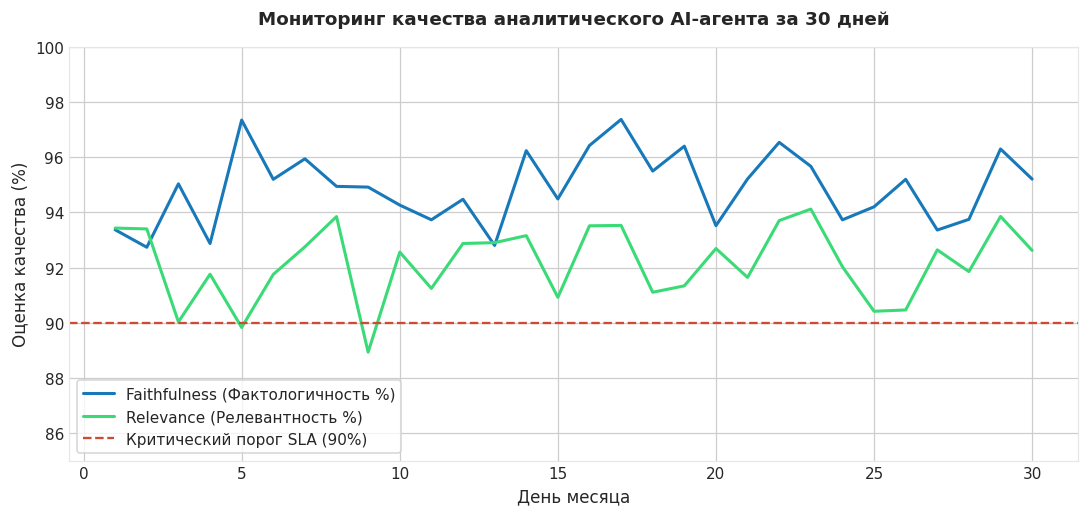

In [3]:
# Визуализация мониторинга агента
fig, ax = plt.subplots(figsize=(10, 4.8), dpi=110)

ax.plot(days, agent_health_df['Faithfulness (%)'], color=PRIMARY, linewidth=2, label='Faithfulness (Фактологичность %)')
ax.plot(days, agent_health_df['Relevance (%)'], color=SUCCESS, linewidth=2, label='Relevance (Релевантность %)')

ax.axhline(90.0, color=ALERT, linestyle='--', label='Критический порог SLA (90%)')

ax.set_title("Мониторинг качества аналитического AI-агента за 30 дней", fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel("День месяца", fontsize=11)
ax.set_ylabel("Оценка качества (%)", fontsize=11)
ax.set_ylim(85, 100)
ax.legend(loc='lower left', frameon=True, facecolor='#ffffff')

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Проверка соблюдения SLA
Убедитесь, что средний показатель Faithfulness за месяц превышает 90%.

In [4]:
### ВАШ КОД ЗДЕСЬ
mean_faith = agent_health_df['Faithfulness (%)'].mean()
print(f"Средняя фактологичность агента: {mean_faith:.1f}%")

assert mean_faith >= 90.0, "Средняя фактологичность должна быть выше 90%"
print("✅ Тест успешно пройден: аналитический агент надежно соответствует SLA!")

Средняя фактологичность агента: 94.9%
✅ Тест успешно пройден: аналитический агент надежно соответствует SLA!


### 💡 Непрерывный цикл улучшений (Quality Flywheel)
Логируйте 100% диалогов агента. Раз в неделю отбирайте сессии с низкой оценкой пользователя (Thumbs Down) и добавляйте их в тестовый бенчмарк (Golden Dataset) для предотвращения регрессий при обновлении промптов.